In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

import pickle
import time
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

In [3]:
df = pd.read_csv('weather_data.csv')
df.drop(columns = ['Unnamed: 0', 'incident_latitude', 'incident_longitude', 'incident_date_created'], inplace=True)
df.head()

,fire_started?,Elevation,temperature_2m_max,temperature_2m_min,daylight_duration,sunshine_duration,uv_index_max,precipitation_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,et0_fao_evapotranspiration,cloud_cover_mean,relative_humidity_2m_max,relative_humidity_2m_min,surface_pressure_max,surface_pressure_min
0,True,142.0,87.857600,49.247600,49805.977,44803.945,7.70,0.0,0.0,8.815597,20.8041,0.244245,42.041668,72.0,16.0,999.06384,995.19250
1,True,634.0,81.365005,60.305000,48694.004,34689.043,8.70,0.0,0.0,25.787672,47.4244,0.356950,31.000000,37.0,9.0,937.44836,931.04100
2,False,1810.0,65.043500,33.723500,49877.473,42414.965,8.50,0.0,0.0,23.492760,31.5417,0.233666,4.708334,48.0,9.0,821.74290,813.92250
3,True,1075.0,82.297390,52.777397,49010.100,45562.844,8.60,0.0,0.0,14.085998,15.2116,0.277917,1.458333,47.0,11.0,897.75420,889.85390
4,True,452.0,93.328700,55.708702,49183.010,45576.700,8.25,0.0,0.0,21.269154,27.5151,0.318660,10.416667,62.0,9.0,962.82263,958.66864


In [4]:
output = df['fire_started?']
input = df.drop(columns = 'fire_started?')
input

,Elevation,temperature_2m_max,temperature_2m_min,daylight_duration,sunshine_duration,uv_index_max,precipitation_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,et0_fao_evapotranspiration,cloud_cover_mean,relative_humidity_2m_max,relative_humidity_2m_min,surface_pressure_max,surface_pressure_min
0,142.0,87.857600,49.247600,49805.977,44803.945,7.70,0.000000,0.0,8.815597,20.804100,0.244245,42.041668,72.0,16.0,999.06384,995.19250
1,634.0,81.365005,60.305000,48694.004,34689.043,8.70,0.000000,0.0,25.787672,47.424400,0.356950,31.000000,37.0,9.0,937.44836,931.04100
2,1810.0,65.043500,33.723500,49877.473,42414.965,8.50,0.000000,0.0,23.492760,31.541700,0.233666,4.708334,48.0,9.0,821.74290,813.92250
3,1075.0,82.297390,52.777397,49010.100,45562.844,8.60,0.000000,0.0,14.085998,15.211600,0.277917,1.458333,47.0,11.0,897.75420,889.85390
4,452.0,93.328700,55.708702,49183.010,45576.700,8.25,0.000000,0.0,21.269154,27.515100,0.318660,10.416667,62.0,9.0,962.82263,958.66864
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1888,119.0,61.258100,54.508100,39140.560,0.000,2.20,0.047244,3.0,9.517114,16.553800,0.022222,99.166664,100.0,78.0,1004.24585,1002.11365
1889,184.0,69.161900,55.571900,38930.830,25391.842,3.35,0.000000,0.0,19.422003,28.857300,0.092696,63.333332,90.0,49.0,996.03630,994.26086
1890,105.0,66.575300,46.235300,38394.273,28767.137,4.40,0.251968,4.0,16.790916,30.199500,0.091072,34.291668,99.0,31.0,1010.39590,1001.46027
1891,2508.0,55.031000,38.021000,38715.902,35558.900,5.25,0.000000,0.0,16.343884,24.383299,0.151837,0.000000,37.0,13.0,761.03485,753.18567


In [5]:
train_X, test_X, train_y, test_y = train_test_split(input, output, test_size = 0.2, random_state= 1)

In [6]:
xg_ml = XGBClassifier(random_state = 1)

In [7]:
start = time.time()
xg_ml.fit(train_X, train_y)
stop = time.time()
print(f"Time Taken: {stop - start} seconds")

Time Taken: 0.2793567180633545 seconds


In [8]:
y_pred = xg_ml.predict(test_X)

In [9]:
class_report = classification_report(test_y, y_pred, output_dict=True)
cr_df = pd.DataFrame(class_report)
cr_df.to_csv('xg_report.csv')
cr_df

,False,True,accuracy,macro avg,weighted avg
precision,0.932203,0.750000,0.891821,0.841102,0.892301
recall,0.929054,0.759036,0.891821,0.844045,0.891821
f1-score,0.930626,0.754491,0.891821,0.842559,0.892053
support,296.000000,83.000000,0.891821,379.000000,379.000000


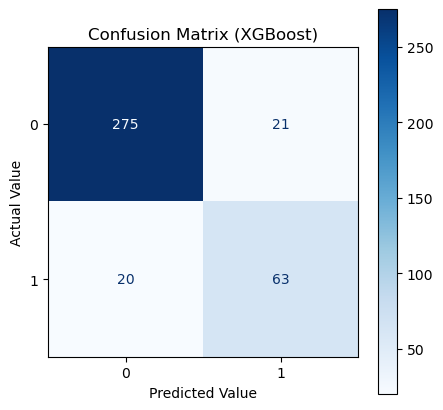

In [14]:
cm = confusion_matrix(test_y, y_pred, labels=xg_ml.classes_)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=xg_ml.classes_)

fig, ax = plt.subplots(figsize=(5,5))
display.plot(cmap = "Blues", ax = ax)
plt.xlabel('Predicted Value')
plt.ylabel('Actual Value')
plt.title('Confusion Matrix (XGBoost)')
plt.savefig('xg_matrix.svg')
fig

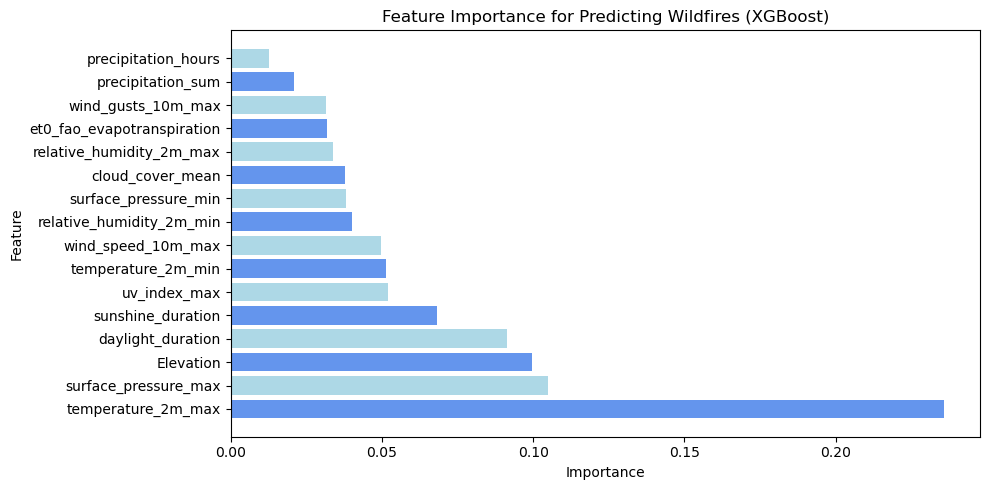

In [15]:
importance = xg_ml.feature_importances_

feat_imp = pd.DataFrame(list(zip(train_X.columns, importance)),
                        columns = ['Feature', 'Importance'])

feat_imp = feat_imp.sort_values(by = 'Importance', ascending=False).reset_index(drop=True)

feat_imp_chart = plt.figure(figsize=(10, 5))
plt.barh(feat_imp['Feature'], feat_imp['Importance'], color = ['#6495ED', '#ADD8E6'])

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance for Predicting Wildfires (XGBoost)')
plt.tight_layout()
plt.savefig('xg_importance.svg')
feat_imp_chart

In [12]:
probability = xg_ml.predict_proba(test_X)
fire_probability = []
for i in probability:
    fire_probability.append(i[1])

fire_probability

[np.float32(0.00042508755),
 np.float32(0.9831119),
 np.float32(0.35383347),
 np.float32(0.9937976),
 np.float32(6.636626e-05),
 np.float32(0.00055626675),
 np.float32(0.20439659),
 np.float32(0.00044158954),
 np.float32(5.1030518e-05),
 np.float32(0.04106773),
 np.float32(0.0006008527),
 np.float32(0.3275918),
 np.float32(0.011530323),
 np.float32(0.0013820075),
 np.float32(0.0022086536),
 np.float32(0.00021808188),
 np.float32(0.014792516),
 np.float32(0.0008078808),
 np.float32(0.09032216),
 np.float32(0.47234255),
 np.float32(0.008317662),
 np.float32(0.99682367),
 np.float32(0.0020881472),
 np.float32(0.00034478548),
 np.float32(0.001107836),
 np.float32(0.9475442),
 np.float32(0.0013340896),
 np.float32(0.0011964662),
 np.float32(0.99024206),
 np.float32(0.0026200574),
 np.float32(0.004228651),
 np.float32(0.00021274936),
 np.float32(0.0005209769),
 np.float32(0.021375366),
 np.float32(0.0035904502),
 np.float32(0.00052377244),
 np.float32(6.014295e-05),
 np.float32(0.00021892438

In [13]:
xg_pickle = open('xg_ml.pickle', 'wb')
pickle.dump(xg_ml, xg_pickle)
xg_pickle.close()